# A/B-тест email-рассылок: анализ эффективности каналов

## 1. Бизнес-контекст

Компания рассылает клиентам промо-письма. Мне нужно ответить на два вопроса:

1. **Работает ли рассылка вообще** — приносит ли письмо дополнительную конверсию по сравнению с ситуацией, когда письмо не отправляется.
2. **Как меняются результаты для каждого письма по сравнению с контролем** и как выглядит экономика рассылки при заданных допущениях.

---

## 2. Дизайн эксперимента

| Параметр | Значение |
|---|---|
| **Группы** | `Mens E-Mail`, `Womens E-Mail`, `No E-Mail` (контроль, письмо не отправлялось) |
| **Единица рандомизации** | клиент (одна строка датасета; идентификатора клиента в данных нет) |
| **Основная метрика (primary)** | **CR** — конверсия (доля клиентов, совершивших покупку) |
| **Вторичные метрики (secondary)** | Visit rate, ARPU, ARPPU, AOV |
| **Экономические метрики** | ROMI, стоимость одной дополнительной конверсии, break-even прирост ARPU |
| **Guardrail-метрика** | в датасете нет (отписки, жалобы на спам). Фиксирую как ограничение: оцениваю только «положительную» сторону эффекта |

---

## 3. Гипотезы

Каждое письмо сравниваю с контролем отдельно, то есть делаю **два сравнения**.

- **H₀:** CR в группе с письмом равна CR в контроле.
- **H₁:** CR отличается (**двусторонний** тест). Беру двусторонний, потому что он покажет и снижение конверсии, а не только рост.

Для выручки (ARPU) гипотезы такие же: H₀ — средняя выручка на клиента одинакова.

Мужское и женское письмо между собой напрямую **не сравниваю** (см. ограничения).

---

## 4. Допущения и параметры

| Параметр | Значение | Комментарий |
|---|---|---|
| Уровень значимости | **α = 0.05** | для каждого теста; из-за двух сравнений использую поправку Холма |
| α при расчёте мощности | **0.025** | 0.05 / 2, поправка Бонферрони на два сравнения |
| Мощность | **1 − β = 0.80** | вероятность заметить эффект, если он есть |
| Стоимость одного письма | **$0.10** | **допущение**, в данных стоимости нет |
| Маржа | **30%** | **допущение**: `spend` это выручка, а не прибыль |

---

## 5. Ограничения анализа

- Нет guardrail-метрик (отписки, жалобы), поэтому побочные эффекты рассылки не оценены.
- Стоимость письма и маржа заданы мной, это не данные. Вывод об окупаемости зависит от них.
- В данных нет `user_id`: нельзя отличить повторные записи одного клиента от разных клиентов с одинаковыми признаками.
- Результат измеряется за короткое окно (две недели после рассылки), долгосрочный эффект неизвестен.
- Данные 2008 года, это историческая кампания: переносить можно методику, а не сами числа.
- Мужское и женское письмо между собой не сравнивал.

In [1]:
# загружаю данные и смотрю структуру
import pandas as pd 
df = pd.read_csv('../data/hillstrom.csv')
df.info()
df.head(5)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64000 entries, 0 to 63999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   recency          64000 non-null  int64  
 1   history_segment  64000 non-null  object 
 2   history          64000 non-null  float64
 3   mens             64000 non-null  int64  
 4   womens           64000 non-null  int64  
 5   zip_code         64000 non-null  object 
 6   newbie           64000 non-null  int64  
 7   channel          64000 non-null  object 
 8   segment          64000 non-null  object 
 9   visit            64000 non-null  int64  
 10  conversion       64000 non-null  int64  
 11  spend            64000 non-null  float64
dtypes: float64(2), int64(6), object(4)
memory usage: 5.9+ MB


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0


## 6. Данные

В файле 64 000 клиентов и 12 колонок. Группа теста лежит в `segment`, результаты — в `visit`, `conversion` и `spend`. Остальные колонки (`recency`, `history`, `history_segment`, `mens`, `womens`, `zip_code`, `newbie`, `channel`) — признаки клиента до рассылки.

Чтобы не запутаться: `mens` и `womens` говорят о том, что клиент покупал раньше, а не о том, какое письмо он получил.

## 7. Проверка данных и рандомизации

In [2]:
# пропуски по столбцам
df.isna().sum()

recency            0
history_segment    0
history            0
mens               0
womens             0
zip_code           0
newbie             0
channel            0
segment            0
visit              0
conversion         0
spend              0
dtype: int64

In [3]:
# полные дубликаты строк
df.duplicated().sum()

np.int64(6562)

In [4]:
df.query('spend>0 and conversion!=1')
# то есть везде, где spend>0, conversion=1. всё в порядке

,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend


**Итог по качеству данных.** Пропусков нет. Везде, где `spend > 0`, стоит `conversion = 1`, противоречий нет. Полных дубликатов 6 562, но **я их не удаляю**: в данных нет `user_id`, поэтому одинаковые строки — скорее всего разные клиенты с одинаковыми признаками (у большинства `visit`, `conversion` и `spend` равны нулю). Если их убрать, вместе с ними уйдёт много не купивших, и конверсия получится завышенной.

In [5]:
# перевожу категориальные признаки в тип category
df = df.astype({
    'segment': 'category',
    'channel': 'category',
    'zip_code': 'category',
    'history_segment': 'category'
})

In [6]:
from scipy.stats import chisquare
obs = df["segment"].value_counts().values
# SRM-тест: если группы поделились примерно поровну, p-value будет большим
chisquare(obs)

Power_divergenceResult(statistic=np.float64(0.20253125000000002), pvalue=np.float64(0.9036929575604196))

In [7]:
from scipy.stats import chi2_contingency

features = ["newbie", "channel", "zip_code", "history_segment"]
results = []

for col in features:
    counts = pd.crosstab(df[col], df['segment'])   # частоты, их нужно для хи-квадрат
    shares = pd.crosstab(df[col], df["segment"], normalize="columns").round(3)   # доли внутри группы, их смотрю глазами
    print(col)
    display(shares)

    chi2, p, dof, _ = chi2_contingency(counts)
    results.append({"feature": col, "chi2": chi2, "dof": dof, "p_value": p})

balance = pd.DataFrame(results)
balance

newbie


segment,Mens E-Mail,No E-Mail,Womens E-Mail
newbie,,,
0,0.498,0.498,0.497
1,0.502,0.502,0.503


channel


segment,Mens E-Mail,No E-Mail,Womens E-Mail
channel,,,
Multichannel,0.121,0.122,0.121
Phone,0.434,0.438,0.442
Web,0.445,0.440,0.437


zip_code


segment,Mens E-Mail,No E-Mail,Womens E-Mail
zip_code,,,
Rural,0.152,0.147,0.149
Surburban,0.446,0.452,0.451
Urban,0.402,0.401,0.400


history_segment


segment,Mens E-Mail,No E-Mail,Womens E-Mail
history_segment,,,
1) $0 - $100,0.363,0.357,0.357
2) $100 - $200,0.220,0.227,0.221
3) $200 - $350,0.192,0.190,0.194
4) $350 - $500,0.098,0.100,0.102
5) $500 - $750,0.075,0.078,0.078
"6) $750 - $1,000",0.030,0.029,0.028
"7) $1,000 +",0.022,0.020,0.020


,feature,chi2,dof,p_value
0,newbie,0.136868,2,0.933855
1,channel,3.632402,4,0.458034
2,zip_code,2.871942,4,0.579479
3,history_segment,13.153292,12,0.357998


**Размеры групп.** 21 307 / 21 306 / 21 387. Хи-квадрат на равные доли даёт p = 0.90, перекоса в размерах нет.

**Категориальные признаки.** По `newbie`, `channel`, `zip_code` и `history_segment` доли в трёх группах почти одинаковые. Хи-квадрат: p от 0.36 (`history_segment`) до 0.93 (`newbie`), значимых различий нет.

--- history ---


,count,mean,std,median
segment,,,,
Mens E-Mail,21307,242.84,260.36,157.22
No E-Mail,21306,240.88,252.74,156.66
Womens E-Mail,21387,242.54,255.33,160.09


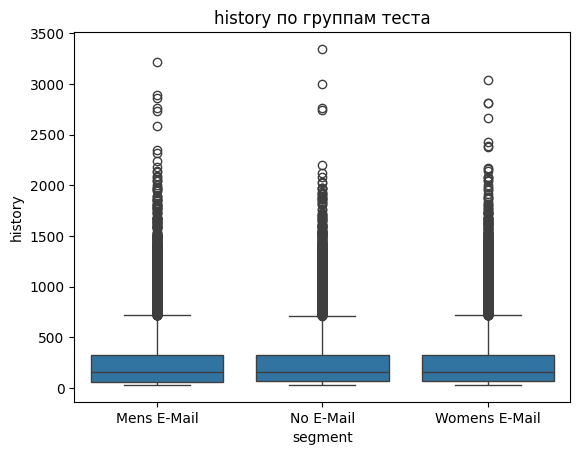

--- recency ---


,count,mean,std,median
segment,,,,
Mens E-Mail,21307,5.77,3.51,6.0
No E-Mail,21306,5.75,3.50,5.0
Womens E-Mail,21387,5.77,3.51,6.0


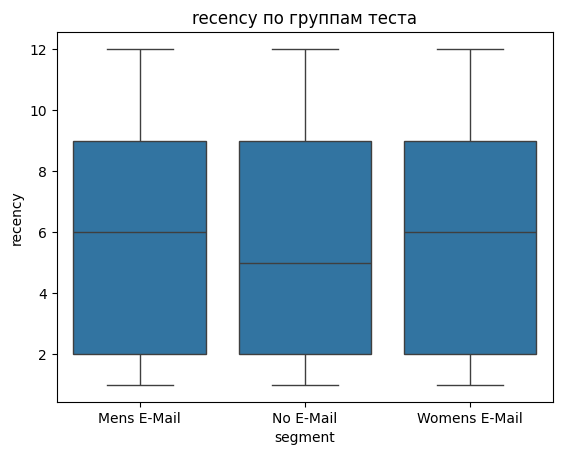

,feature,F,p_value,eta2
0,history,0.359487,0.698036,0.000011
1,recency,0.270389,0.763083,0.000008


In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import f_oneway

num_features = ["history", "recency"]
order = list(df["segment"].cat.categories)
results_num = []

for col in num_features:
    # 1. Описательные статистики по группам
    print(f"--- {col} ---")
    display(df.groupby("segment", observed=True)[col]
            .agg(["count", "mean", "std", "median"]).round(2))

    # 2. Boxplot
    sns.boxplot(data=df, x="segment", y=col, order=order)
    plt.title(f"{col} по группам теста")
    plt.show()

    # 3. ANOVA: равны ли средние в трёх группах
    samples = [df.loc[df["segment"] == g, col] for g in order]
    f_stat, p_value = f_oneway(*samples)

    # 4. Размер эффекта (eta-квадрат): какую долю разброса объясняет группа
    grand_mean = df[col].mean()
    ss_between = sum(len(s) * (s.mean() - grand_mean) ** 2 for s in samples)
    ss_total = ((df[col] - grand_mean) ** 2).sum()
    eta2 = ss_between / ss_total

    results_num.append({"feature": col, "F": f_stat, "p_value": p_value, "eta2": eta2})

pd.DataFrame(results_num)

**Числовые признаки.** Средние `history` (240.9–242.8) и `recency` (5.75–5.77) в группах практически совпадают. ANOVA: p = 0.70 для `history` и 0.76 для `recency`, eta² около 0.00001, то есть принадлежность к группе почти ничего не объясняет. У `history` длинный правый хвост (редкие клиенты с большими тратами), но во всех трёх группах он выглядит одинаково.

**Вывод по рандомизации:** группы сбалансированы, их можно сравнивать напрямую.

In [9]:
def calc_metrics(df, group_col="segment"):
    g = df.groupby(group_col, observed=True)
    buyers = df[df["conversion"] == 1].groupby(group_col, observed=True)
    return pd.DataFrame({
        "n": g.size(),
        "visit_rate": g["visit"].mean(),
        "cr": g["conversion"].mean(),
        "arpu": g["spend"].mean(),                          # выручка на всех клиентов группы
        "arppu": buyers["spend"].mean(),                    # выручка на купившего
        "aov": g["spend"].sum() / g["conversion"].sum(),    # здесь conversion = 0/1 на клиента, поэтому aov совпадает с arppu
    })

In [10]:
# сводная таблица базовых метрик по группам
calc_metrics(df)

,n,visit_rate,cr,arpu,arppu,aov
segment,,,,,,
Mens E-Mail,21307,0.182757,0.012531,1.422617,113.526929,113.526929
No E-Mail,21306,0.106167,0.005726,0.652789,114.002705,114.002705
Womens E-Mail,21387,0.151400,0.008837,1.077202,121.894762,121.894762


In [11]:
# доля клиентов без покупки
percent = len(df[df['spend'] == 0]) / len(df['spend'])
percent

0.99096875

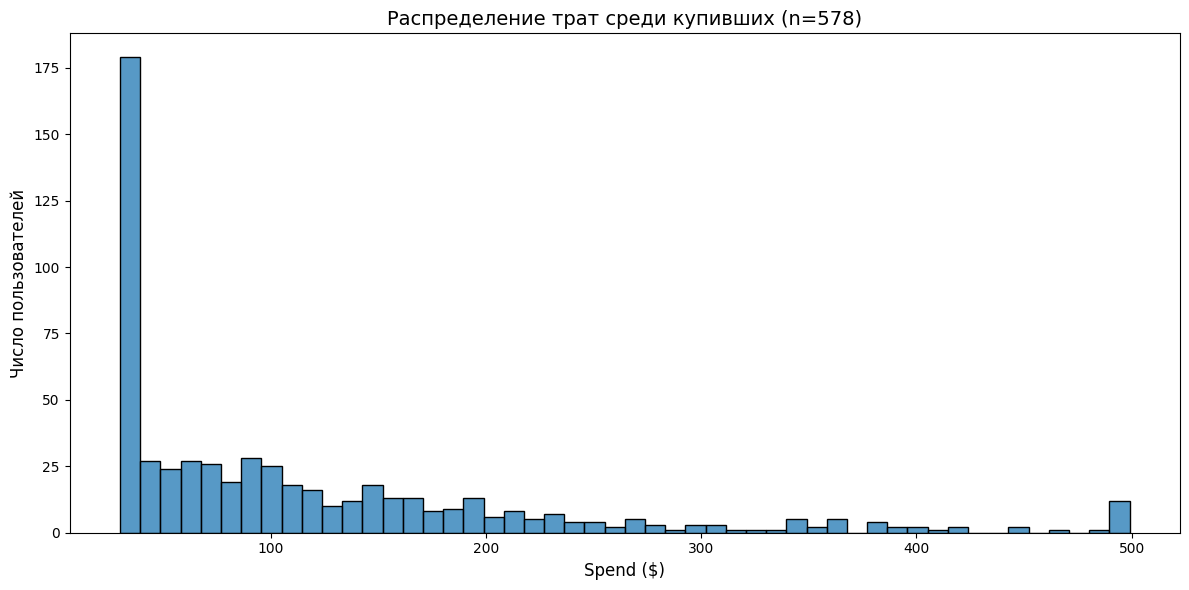

In [12]:
# распределение трат только среди купивших (spend > 0)
spend_positive = df.loc[df['spend'] > 0, 'spend']
fig, ax = plt.subplots(figsize=(12, 6))

sns.histplot(spend_positive, bins=50)

ax.set_title(f'Распределение трат среди купивших (n={len(spend_positive):,})', fontsize=14)
ax.set_xlabel('Spend ($)', fontsize=12)
ax.set_ylabel('Число пользователей', fontsize=12)

plt.tight_layout()
plt.show()

**Про `spend`.** 99.1% клиентов ничего не купили (`spend = 0`), покупателей всего 578. У купивших распределение скошено вправо: больше всего небольших чеков и длинный хвост примерно до 500 $. Для таких данных нормальность не выполняется, а среднее держится на небольшом числе покупателей. Поэтому для выручки дальше использую тест Уэлча и bootstrap, а не один обычный t-тест.

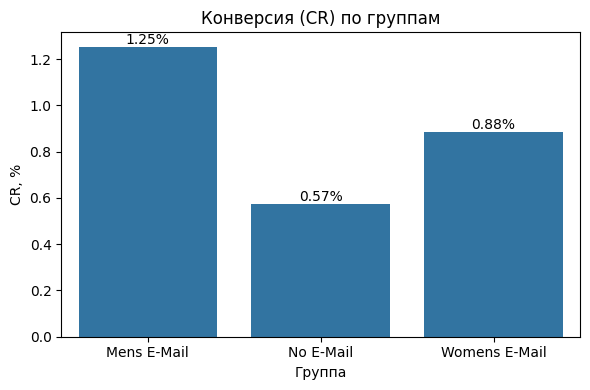

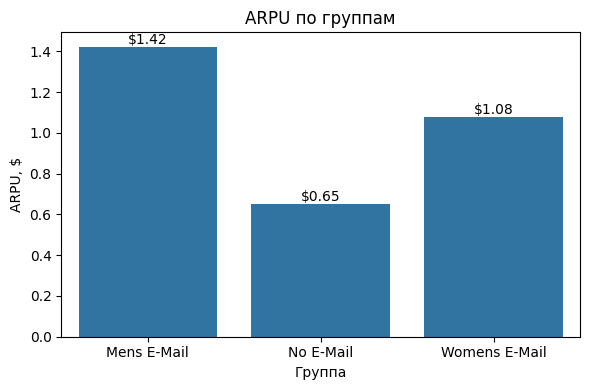

In [13]:
import os
# 1. Папка для графиков
os.makedirs("../reports", exist_ok=True)

# 2. Метрики по группам
order = list(df["segment"].cat.categories)   # порядок групп из данных
metrics = (df.groupby("segment", observed=True)
             .agg(cr=("conversion", "mean"), arpu=("spend", "mean"))
             .loc[order])
metrics["cr_pct"] = metrics["cr"] * 100      # конверсия в процентах

# 3. График CR
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=metrics.index, y=metrics["cr_pct"], order=order, ax=ax)
ax.bar_label(ax.containers[0], fmt="%.2f%%")
ax.set_title("Конверсия (CR) по группам")
ax.set_xlabel("Группа")
ax.set_ylabel("CR, %")
fig.tight_layout()
fig.savefig("../reports/cr_by_group.png", dpi=150)
plt.show()

# 4. График ARPU
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=metrics.index, y=metrics["arpu"], order=order, ax=ax)
ax.bar_label(ax.containers[0], fmt="$%.2f")
ax.set_title("ARPU по группам")
ax.set_xlabel("Группа")
ax.set_ylabel("ARPU, $")
fig.tight_layout()
fig.savefig("../reports/arpu_by_group.png", dpi=150)
plt.show()

**Первый взгляд на метрики.** CR: контроль 0.57%, женское письмо 0.88%, мужское 1.25%. ARPU: $0.65, $1.08 и $1.42 соответственно. На обоих графиках порядок групп один и тот же. Это пока точечные оценки без доверительных интервалов, значимость проверяю ниже.

## 8. Мощность и MDE

In [14]:
import numpy as np
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

alpha = 0.05 / 2      # два сравнения с контролем, поправка Бонферрони
power = 0.80

control_name = "No E-Mail"   # название контрольной группы в данных

p0 = df.loc[df["segment"] == control_name, "conversion"].mean()
n_control = (df["segment"] == control_name).sum()

print(p0, n_control)   # проверяю: p0 около 0.0057, группа около 21 300
analysis = NormalIndPower()

0.005726086548390125 21306


In [15]:
# сколько клиентов на группу нужно, чтобы заметить эффект заданного размера
for mde_rel in [0.10, 0.20, 0.30, 0.50]:
    p1 = p0 * (1 + mde_rel)
    h = proportion_effectsize(p1, p0)
    n = analysis.solve_power(effect_size=h, alpha=alpha, power=power,
                             ratio=1, alternative="two-sided")
    print(f"MDE {mde_rel:.0%}: нужно {int(np.ceil(n))} клиентов на группу")

MDE 10%: нужно 346299 клиентов на группу
MDE 20%: нужно 90536 клиентов на группу
MDE 30%: нужно 41963 клиентов на группу
MDE 50%: нужно 16316 клиентов на группу


In [16]:
# обратная задача: какой минимальный эффект заметит тест при моём размере группы
h_min = analysis.solve_power(nobs1=n_control, alpha=alpha, power=power,
                             ratio=1, alternative="two-sided")
p1_min = np.sin(h_min / 2 + np.arcsin(np.sqrt(p0))) ** 2
print(f"Минимально обнаружимый эффект: {p1_min - p0:.4%} (абс.), "
      f"{(p1_min - p0) / p0:.1%} (отн.)")

Минимально обнаружимый эффект: 0.2474% (абс.), 43.2% (отн.)


**Мощность и MDE.** Базовая конверсия контроля p0 = 0.5726%, в группе 21 306 клиентов. При α = 0.025 и мощности 80% чтобы заметить рост на 10% (отн.) нужно около 346 тыс. клиентов на группу, на 20% — около 90.5 тыс., на 30% — около 42 тыс., на 50% — около 16.3 тыс.

Моя выборка (≈21.3 тыс. на группу) замечает эффект от **0.25 п.п., то есть около +43% отн.** (с 0.57% до 0.82%). Меньшие эффекты тест мог бы и пропустить. Наблюдаемые эффекты (+119% и +54%) выше этого порога, так что тест достаточно чувствителен для того, что мы увидели.

## 9. Результаты теста

In [17]:
# конверсия: Z-тест для двух долей и 95% ДИ для разницы, каждое письмо против контроля
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

control_name = "No E-Mail"
treat_groups = ["Mens E-Mail", "Womens E-Mail"]

c = df[df["segment"] == control_name]
rows = []

for g in treat_groups:
    t = df[df["segment"] == g]
    x = np.array([t["conversion"].sum(), c["conversion"].sum()])   # число купивших
    n = np.array([len(t), len(c)])                                 # размеры групп

    z, p = proportions_ztest(x, n, alternative="two-sided")
    low, high = confint_proportions_2indep(x[0], n[0], x[1], n[1],
                                           compare="diff", alpha=0.05)

    cr_t, cr_c = x[0] / n[0], x[1] / n[1]
    rows.append({
        "group": g,
        "cr_test": cr_t,
        "cr_control": cr_c,
        "uplift_abs_pp": (cr_t - cr_c) * 100,
        "uplift_rel": (cr_t - cr_c) / cr_c,
        "ci_low_pp": low * 100,
        "ci_high_pp": high * 100,
        "z": z,
        "p_raw": p,
    })

cr_res = pd.DataFrame(rows)
cr_res

,group,cr_test,cr_control,uplift_abs_pp,uplift_rel,ci_low_pp,ci_high_pp,z,p_raw
0,Mens E-Mail,0.012531,0.005726,0.680501,1.188422,0.501434,0.864072,7.385114,1.523224e-13
1,Womens E-Mail,0.008837,0.005726,0.311106,0.543313,0.150166,0.474547,3.779561,1.571051e-04


In [18]:
# выручка (spend): тест Уэлча и bootstrap-интервал для разницы ARPU
from scipy import stats

rng = np.random.default_rng(42)
cc = df.loc[df["segment"] == control_name, "spend"].to_numpy()
rows = []

for g in treat_groups:
    tt = df.loc[df["segment"] == g, "spend"].to_numpy()

    t_stat, p = stats.ttest_ind(tt, cc, equal_var=False)

    diffs = np.array([
        rng.choice(tt, size=len(tt)).mean() - rng.choice(cc, size=len(cc)).mean()
        for _ in range(5000)
    ])
    low, high = np.percentile(diffs, [2.5, 97.5])

    rows.append({
        "group": g,
        "arpu_test": tt.mean(),
        "arpu_control": cc.mean(),
        "uplift_abs": tt.mean() - cc.mean(),
        "uplift_rel": (tt.mean() - cc.mean()) / cc.mean(),
        "ci_low": low,
        "ci_high": high,
        "t": t_stat,
        "p_raw": p,
    })

spend_res = pd.DataFrame(rows)
spend_res

,group,arpu_test,arpu_control,uplift_abs,uplift_rel,ci_low,ci_high,t,p_raw
0,Mens E-Mail,1.422617,0.652789,0.769827,1.179289,0.479081,1.049206,5.300140,1.163815e-07
1,Womens E-Mail,1.077202,0.652789,0.424412,0.650152,0.165704,0.694248,3.256372,1.129397e-03


In [19]:
# поправка Холма на два сравнения (отдельно для CR и для ARPU)
from statsmodels.stats.multitest import multipletests

cr_res["p_holm"] = multipletests(cr_res["p_raw"], alpha=0.05, method="holm")[1]
spend_res["p_holm"] = multipletests(spend_res["p_raw"], alpha=0.05, method="holm")[1]

cr_res["significant"] = cr_res["p_holm"] < 0.05
spend_res["significant"] = spend_res["p_holm"] < 0.05

display(cr_res.round(5))
display(spend_res.round(4))

,group,cr_test,cr_control,uplift_abs_pp,uplift_rel,ci_low_pp,ci_high_pp,z,p_raw,p_holm,significant
0,Mens E-Mail,0.01253,0.00573,0.68050,1.18842,0.50143,0.86407,7.38511,0.00000,0.00000,True
1,Womens E-Mail,0.00884,0.00573,0.31111,0.54331,0.15017,0.47455,3.77956,0.00016,0.00016,True


,group,arpu_test,arpu_control,uplift_abs,uplift_rel,ci_low,ci_high,t,p_raw,p_holm,significant
0,Mens E-Mail,1.4226,0.6528,0.7698,1.1793,0.4791,1.0492,5.3001,0.0000,0.0000,True
1,Womens E-Mail,1.0772,0.6528,0.4244,0.6502,0.1657,0.6942,3.2564,0.0011,0.0011,True


Каждое письмо сравниваю с контролем, поправка Холма на два сравнения.

**Конверсия**
- Мужское письмо: 1.25% против 0.57% в контроле, **+0.68 п.п. (+119% отн.)**, 95% ДИ разницы 0.50–0.86 п.п., z = 7.39, p_holm < 0.0001.
- Женское письмо: 0.88% против 0.57%, **+0.31 п.п. (+54% отн.)**, ДИ 0.15–0.47 п.п., z = 3.78, p_holm = 0.00016.

**ARPU** (тест Уэлча, bootstrap)
- Мужское: $1.42 против $0.65, **+$0.77**, ДИ $0.48–$1.05, p_holm < 0.0001.
- Женское: $1.08 против $0.65, **+$0.42**, ДИ $0.17–$0.69, p_holm = 0.0011.

Оба письма значимо повышают и конверсию, и выручку на клиента. Все доверительные интервалы лежат выше нуля, а bootstrap-интервал согласуется с тестом Уэлча.

Мужское письмо даёт больший эффект, и интервалы эффектов по CR почти не пересекаются. Но это не тест: между собой письма я напрямую не сравнивал, поэтому «мужское лучше женского» как доказанный факт не записываю.

## 10. Сегментный анализ

In [20]:
# где эффект сильнее: те же Z-тесты внутри сегментов, контроль берётся из того же сегмента
# поправка Холма сразу на все 16 сравнений
segment_features = ["newbie", "channel", "zip_code"]
rows = []

for feat in segment_features:
    for val in sorted(df[feat].unique()):
        sub = df[df[feat] == val]
        c = sub[sub["segment"] == control_name]

        for g in treat_groups:
            t = sub[sub["segment"] == g]
            x = np.array([t["conversion"].sum(), c["conversion"].sum()])
            n = np.array([len(t), len(c)])

            z, p = proportions_ztest(x, n, alternative="two-sided")
            rows.append({
                "feature": feat, "value": val, "group": g,
                "n_test": n[0], "n_control": n[1],
                "buyers_test": x[0], "buyers_control": x[1],
                "cr_test": x[0] / n[0], "cr_control": x[1] / n[1],
                "uplift_abs_pp": (x[0] / n[0] - x[1] / n[1]) * 100,
                "p_raw": p,
            })

seg_res = pd.DataFrame(rows)
seg_res["p_holm"] = multipletests(seg_res["p_raw"], alpha=0.05, method="holm")[1]
seg_res["significant"] = seg_res["p_holm"] < 0.05
seg_res.round(4)

,feature,value,group,n_test,n_control,buyers_test,buyers_control,cr_test,cr_control,uplift_abs_pp,p_raw,p_holm,significant
0,newbie,0,Mens E-Mail,10621,10611,148,82,0.0139,0.0077,0.6207,0.0000,0.0001,True
1,newbie,0,Womens E-Mail,10624,10611,92,82,0.0087,0.0077,0.0932,0.4514,0.4514,False
2,newbie,1,Mens E-Mail,10686,10695,119,40,0.0111,0.0037,0.7396,0.0000,0.0000,True
3,newbie,1,Womens E-Mail,10763,10695,97,40,0.0090,0.0037,0.5272,0.0000,0.0000,True
4,channel,Multichannel,Mens E-Mail,2577,2606,44,18,0.0171,0.0069,1.0167,0.0008,0.0069,True
5,channel,Multichannel,Womens E-Mail,2579,2606,36,18,0.0140,0.0069,0.7052,0.0124,0.0743,False
6,channel,Phone,Mens E-Mail,9240,9327,100,50,0.0108,0.0054,0.5462,0.0000,0.0003,True
7,channel,Phone,Womens E-Mail,9454,9327,67,50,0.0071,0.0054,0.1726,0.1328,0.3983,False
8,channel,Web,Mens E-Mail,9490,9373,123,54,0.0130,0.0058,0.7200,0.0000,0.0000,True
9,channel,Web,Womens E-Mail,9354,9373,86,54,0.0092,0.0058,0.3433,0.0064,0.0474,True


Это поисковый анализ: сегментов много, поэтому поправка Холма считается на все 16 сравнений.

**Мужское письмо** даёт положительный эффект во всех 8 сегментах, от +0.53 до +1.02 п.п., значимо в семи. Единственный незначимый сегмент — `Rural` (p_holm = 0.17), но там мало покупателей (44 и 26), так что это больше про размер выборки. Эффект получился однородным, выделять отдельную аудиторию не вижу оснований.

**Женское письмо** ведёт себя менее ровно:
- `newbie = 1`: +0.53 п.п., значимо; `newbie = 0`: +0.09 п.п., p = 0.45;
- по каналам значимо только `Web` (p_holm = 0.047), `Multichannel` на границе (+0.71 п.п., p_holm = 0.074), `Phone` слабый (+0.17 п.п.);
- по регионам значим только `Urban` (p_holm = 0.047).

Оговорки: (1) если в одном сегменте p < 0.05, а в другом нет, это ещё не доказывает, что эффекты разные, для этого нужен отдельный тест взаимодействия, который я не делал; (2) в сегментах от 18 до 148 покупателей, а два значимых результата для женского письма (`Web`, `Urban`) лежат почти у порога (≈0.047). Поэтому записываю это как **гипотезу для следующего теста**, а не как факт.

## 11. Экономика кампании

In [21]:
# переводим эффект в деньги. cost_per_email и margin — мои допущения, в данных их нет
cost_per_email = 0.10   # допущение: стоимость одного письма, $
margin = 0.30           # допущение: доля прибыли в выручке (spend это выручка, а не прибыль)

econ = (cr_res[["group", "uplift_abs_pp"]]
        .merge(spend_res[["group", "uplift_abs", "ci_low", "ci_high"]], on="group"))

econ["n_test"] = econ["group"].map(df["segment"].value_counts())

econ["inc_conversions"] = econ["uplift_abs_pp"] / 100 * econ["n_test"]
econ["inc_revenue"] = econ["uplift_abs"] * econ["n_test"]
econ["cost"] = cost_per_email * econ["n_test"]
econ["inc_profit"] = econ["inc_revenue"] * margin - econ["cost"]
econ["romi"] = econ["inc_profit"] / econ["cost"]
econ["cost_per_inc_conv"] = econ["cost"] / econ["inc_conversions"]
econ["profit_per_1000"] = econ["inc_profit"] / econ["n_test"] * 1000
econ["profit_per_1000_low"] = (econ["ci_low"] * margin - cost_per_email) * 1000
econ["profit_per_1000_high"] = (econ["ci_high"] * margin - cost_per_email) * 1000

breakeven_uplift = cost_per_email / margin
print(f"Break-even прирост ARPU: ${breakeven_uplift:.3f} на клиента")
econ.round(2)

Break-even прирост ARPU: $0.333 на клиента


,group,uplift_abs_pp,uplift_abs,ci_low,ci_high,n_test,inc_conversions,inc_revenue,cost,inc_profit,romi,cost_per_inc_conv,profit_per_1000,profit_per_1000_low,profit_per_1000_high
0,Mens E-Mail,0.68,0.77,0.48,1.05,21307,144.99,16402.71,2130.7,2790.11,1.31,14.70,130.95,43.72,214.76
1,Womens E-Mail,0.31,0.42,0.17,0.69,21387,66.54,9076.90,2138.7,584.37,0.27,32.14,27.32,-50.29,108.27


In [22]:
# чувствительность: прибыль на 1000 клиентов при разных ценах письма и марже
costs = [0.05, 0.10, 0.20, 0.50]
margins = [0.2, 0.3, 0.5, 1.0]

for g in treat_groups:
    arpu_gain = econ.loc[econ["group"] == g, "uplift_abs"].iloc[0]
    grid = pd.DataFrame(
        [[(arpu_gain * m - c) * 1000 for m in margins] for c in costs],
        index=[f"${c}" for c in costs],
        columns=[f"margin {m:.0%}" for m in margins],
    )
    print(g, "— прибыль на 1000 клиентов, $")
    display(grid.round(0))

Mens E-Mail — прибыль на 1000 клиентов, $


,margin 20%,margin 30%,margin 50%,margin 100%
$0.05,104.0,181.0,335.0,720.0
$0.1,54.0,131.0,285.0,670.0
$0.2,-46.0,31.0,185.0,570.0
$0.5,-346.0,-269.0,-115.0,270.0


Womens E-Mail — прибыль на 1000 клиентов, $


,margin 20%,margin 30%,margin 50%,margin 100%
$0.05,35.0,77.0,162.0,374.0
$0.1,-15.0,27.0,112.0,324.0
$0.2,-115.0,-73.0,12.0,224.0
$0.5,-415.0,-373.0,-288.0,-76.0


**Что получилось при допущениях (письмо $0.10, маржа 30%).** Break-even прирост ARPU равен 0.10 / 0.30 = $0.33 на клиента.

| | Мужское | Женское |
|---|---|---|
| Дополнительные покупатели | ≈145 | ≈67 |
| Дополнительная прибыль после затрат | ≈$2 790 | ≈$584 |
| ROMI | 1.31 | 0.27 |
| Стоимость одного дополнительного покупателя | $14.70 | $32.14 |
| Прибыль на 1000 клиентов (95% ДИ) | $131 ([$44; $215]) | $27 ([−$50; $108]) |

У мужского письма прирост ARPU ($0.77) и даже нижняя граница интервала ($0.48) выше break-even, интервал прибыли целиком положительный, рассылка окупается уверенно. У женского прирост ($0.42) выше порога, но нижняя граница ($0.17) ниже него, интервал прибыли захватывает ноль. Поэтому про женское письмо я могу сказать только, что окупаемость **не гарантирована**, а не что оно убыточно.

Таблица чувствительности показывает, что вывод зависит от цены письма и маржи: при дорогом письме или низкой марже мужское письмо тоже перестаёт быть прибыльным.

## 12. Итоги

1. Рандомизация прошла корректно (SRM p = 0.90, баланс признаков p от 0.36 до 0.93).
2. Оба письма значимо повышают конверсию и ARPU: мужское на +0.68 п.п. и +$0.77, женское на +0.31 п.п. и +$0.42.
3. При принятых допущениях мужское письмо окупается уверенно (ROMI 1.31), женское — под вопросом (ROMI 0.27, интервал прибыли захватывает ноль).
4. По сегментам эффект мужского письма однородный; у женского он, возможно, выше среди новых клиентов (гипотеза).

**Что бы я сделал дальше:** напрямую сравнил мужское и женское письмо (тогда Холм считается на три сравнения), проверил взаимодействие письмо × `newbie`, добавил CUPED с `history` для снижения дисперсии ARPU. В этой работе я этого не делал.

**Ограничения:** см. раздел 5. Главные из них: данные 2008 года, окно две недели, нет guardrail-метрик и `user_id`, а стоимость письма и маржа взяты как допущения.